# Regime-conditional multi-asset allocation (India)

The single-index overlay in `regime-filtered.ipynb` did not beat a plain vol rule. This notebook tests the other use of regimes: **change how a basket of assets is combined**, not whether to hold the index.

**Universe:** Nifty 50, Nifty Bank, Nifty Midcap 50, Gold (GOLDBEES), plus cash at a flat 6%. Equity series are *price* indices (no dividends); this biases all equities down equally, gold ETF has no distributions.
**Regimes:** the same walk-forward *filtered* 3-state diagonal HMM on Nifty + India VIX features, now on a much longer history (2009 -> 2026), so the out-of-sample window (2012 -> 2026) contains the 2013 taper, 2018, Covid 2020, 2022 and the 2026 gold sell-off.

**Allocation rule (all hyper-parameters fixed before looking at results):**

| Item | Setting |
|---|---|
| Per-state moments | posterior-weighted mean/cov of asset returns from each fold's **train window only**; means shrunk 70% and covariances 20% toward pooled |
| Blend | `mu_t = sum p_k mu_k`, `Sigma_t = sum p_k (Sigma_k + mu_k mu_k') - mu_t mu_t'` with the *filtered* `p_t` |
| Optimiser | long-only, `max mu'w - (4/2) w'Sigma w`, each risky asset capped at 60%, cash allowed |
| Rebalance | decision every 5 trading days; **trade at the next close, earn from the day after**; 10 bps per unit traded |

**Ablations that isolate the regime effect:** *Static MV* (same optimiser and shrinkage, no regimes), *Regime risk-only* (regime-dependent covariance but pooled means, because means are the noisy part), plus Equal weight, Inverse-vol and Nifty buy & hold.


In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import regime_filter as rf, regime_allocation as ra

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
RF, COST = 0.06, 10.0

px = ra.download_assets()          # cached in multiasset_prices.csv; outlier-filtered
R_all = px[ra.RISKY].pct_change().dropna()
print(f"{px.index.min().date()} -> {px.index.max().date()}  ({len(px)} rows)")
summary = pd.DataFrame({"ann_return": R_all.mean() * 252, "ann_vol": R_all.std() * np.sqrt(252),
                        "max_1d_move": R_all.abs().max()})
display(summary.round(3)); display(R_all.corr().round(2))

2009-01-02 -> 2026-10-16  (4323 rows)


,ann_return,ann_vol,max_1d_move
nifty,0.135,0.181,0.177
bank,0.169,0.246,0.188
midcap,0.171,0.226,0.149
gold,0.141,0.159,0.105


,nifty,bank,midcap,gold
nifty,1.00,0.89,0.83,-0.01
bank,0.89,1.00,0.77,-0.04
midcap,0.83,0.77,1.00,-0.02
gold,-0.01,-0.04,-0.02,1.00


## 1. Walk-forward filtered regimes on the long history

OOS 2012-03-06 -> 2026-10-16 (3547 days, 29 refits)
Share of OOS days by argmax state: {'S0': 0.617, 'S1': 0.298, 'S2': 0.085}
Mean entropy 0.056, days with max-prob<0.6: 1.2%


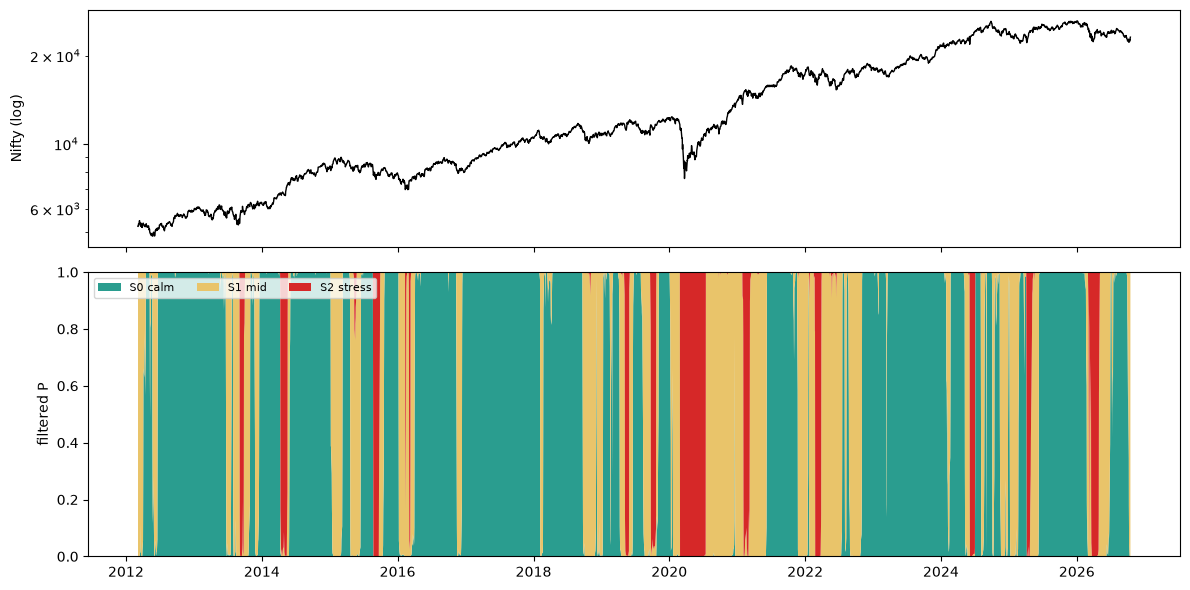

In [2]:
df = pd.DataFrame({"close": px["nifty"], "vix": px["vix"]})
feats = rf.build_features(df)
ret = df["close"].pct_change().reindex(feats.index)
res = rf.walk_forward(feats, ret, rf.WFConfig(n_states=3, cov_type="diag", warmup_days=756, refit_days=126, n_init=10, seed=42))
P = res.probs
R = R_all.reindex(feats.index).dropna()
print(f"OOS {P.index.min().date()} -> {P.index.max().date()} ({len(P)} days, {len(res.folds)} refits)")
print("Share of OOS days by argmax state:", P.idxmax(axis=1).value_counts(normalize=True).sort_index().round(3).to_dict())
print("Mean entropy %.3f, days with max-prob<0.6: %.1f%%" % (rf.entropy(P).mean(), 100 * (P.max(axis=1) < 0.6).mean()))

cols = ["#2a9d8f", "#e9c46a", "#d62828"]
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})
ax[0].plot(px["nifty"].reindex(P.index), color="black", lw=1); ax[0].set_yscale("log"); ax[0].set_ylabel("Nifty (log)")
ax[1].stackplot(P.index, P.T.values, colors=cols, labels=["S0 calm", "S1 mid", "S2 stress"]); ax[1].set_ylim(0, 1)
ax[1].legend(loc="upper left", ncol=3, fontsize=8); ax[1].set_ylabel("filtered P")
plt.tight_layout(); plt.show()

## 2. Do regimes actually change cross-asset behaviour? (the premise)

Realised **next-day** return statistics conditioned on today's *filtered* argmax regime (no hindsight). If the premise is true we should see different volatilities and, importantly, different *correlations* (e.g. gold vs equities) by regime.

In [3]:
hard = P.idxmax(axis=1)
nxt = R.reindex(P.index).shift(-1)          # return on t+1, regime known at t
rows = []
for k in sorted(hard.unique()):
    x = nxt[hard == k].dropna()
    rows.append(pd.concat([(x.mean() * 252).rename(lambda c: f"ret_{c}"), (x.std() * np.sqrt(252)).rename(lambda c: f"vol_{c}")]).rename(k))
cond = pd.DataFrame(rows); cond["days"] = hard.value_counts().sort_index()
display(cond.round(3))
corr = pd.DataFrame({k: {"gold~nifty": nxt[hard == k][["gold", "nifty"]].corr().iloc[0, 1],
                         "bank~nifty": nxt[hard == k][["bank", "nifty"]].corr().iloc[0, 1],
                         "midcap~nifty": nxt[hard == k][["midcap", "nifty"]].corr().iloc[0, 1]} for k in sorted(hard.unique())})
print("Next-day correlations by regime:"); display(corr.round(2))

,ret_nifty,ret_bank,ret_midcap,ret_gold,vol_nifty,vol_bank,vol_midcap,vol_gold,days
S0,0.049,0.080,0.050,0.134,0.121,0.164,0.184,0.147,2187
S1,0.165,0.212,0.258,0.101,0.175,0.245,0.228,0.155,1057
S2,0.466,0.407,0.693,0.079,0.307,0.430,0.332,0.211,303


Next-day correlations by regime:


,S0,S1,S2
gold~nifty,-0.04,-0.07,0.08
bank~nifty,0.86,0.88,0.92
midcap~nifty,0.78,0.84,0.89


## 3. Strategies

In [4]:
idx = P.index
tg = ra.build_targets(res, R, rf_annual=RF, rebal_every=5, risk_aversion=4.0, cap=0.6, lam_mean=0.7, lam_cov=0.2)
nifty_only = pd.DataFrame({"nifty": 1.0, "bank": 0.0, "midcap": 0.0, "gold": 0.0, "cash": 0.0}, index=tg["Equal weight"].index[:1])
tg["Nifty B&H"] = nifty_only

rets, Ws, turn = {}, {}, {}
for n, t in tg.items():
    rets[n], Ws[n], turn[n] = ra.simulate(t, R, rf_annual=RF, cost_bps=COST, index=idx)
tab = pd.DataFrame({n: rf.perf(r, None, RF) for n, r in rets.items()})
tab.loc["AnnTurnover"] = pd.Series(turn)
tab.loc["AvgCash"] = pd.Series({n: Ws[n]["cash"].mean() for n in Ws})
tab.round(3)

,Regime MV,Regime risk-only,Static MV,Inverse vol,Equal weight,Nifty B&H
CAGR,0.107,0.106,0.125,0.129,0.135,0.112
AnnVol,0.145,0.142,0.141,0.130,0.144,0.162
Sharpe,0.373,0.373,0.496,0.548,0.546,0.376
Sortino,0.521,0.524,0.697,0.756,0.751,0.518
MaxDD,-0.275,-0.254,-0.318,-0.312,-0.334,-0.384
Calmar,0.390,0.419,0.395,0.413,0.404,0.291
AnnTurnover,5.872,3.975,1.019,0.753,0.625,0.000
AvgCash,0.010,0.019,0.000,0.000,0.000,0.000


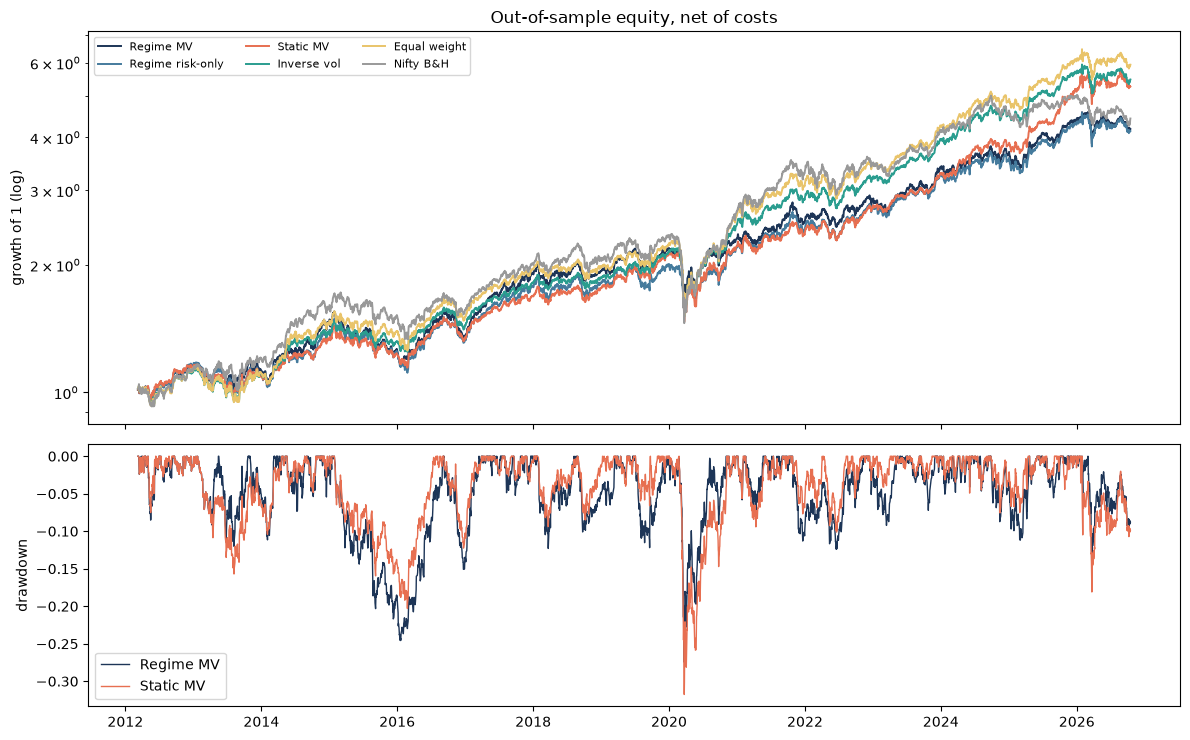

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
palette = {"Regime MV": "#1d3557", "Regime risk-only": "#457b9d", "Static MV": "#e76f51", "Inverse vol": "#2a9d8f", "Equal weight": "#e9c46a", "Nifty B&H": "#999999"}
for n, r in rets.items():
    ax[0].plot((1 + r).cumprod(), label=n, color=palette[n], lw=1.4)
ax[0].set_yscale("log"); ax[0].legend(ncol=3, fontsize=8); ax[0].set_ylabel("growth of 1 (log)"); ax[0].set_title("Out-of-sample equity, net of costs")
for n in ["Regime MV", "Static MV"]:
    dd = (1 + rets[n]).cumprod(); ax[1].plot(dd / dd.cummax() - 1, label=n, color=palette[n], lw=1)
ax[1].set_ylabel("drawdown"); ax[1].legend()
plt.tight_layout(); plt.show()

### What does the regime-aware portfolio actually hold?
Average *realised* weights, split by the filtered regime on the decision day. If the regime signal is doing something sensible, the stressed state should look different from the calm one (e.g. more gold/cash).

In [6]:
w = Ws["Regime MV"]
st = hard.shift(2).reindex(w.index)   # regime known when the trade was decided (2-day execution lag)
display(w.groupby(st).mean().round(3).assign(days=w.groupby(st).size()))
print("Static MV average weights:"); display(Ws["Static MV"].mean().round(3).to_frame("w").T)

,nifty,bank,midcap,gold,cash,days
S0,0.166,0.580,0.128,0.125,0.001,2187
S1,0.044,0.365,0.093,0.468,0.030,1055
S2,0.020,0.301,0.171,0.506,0.002,303


Static MV average weights:


,nifty,bank,midcap,gold,cash
w,0.007,0.435,0.118,0.44,0.0


### Is any difference distinguishable from noise?
Paired moving-block bootstrap of Sharpe differences (20-day blocks, 2000 draws). The relevant comparisons are against *Static MV* (pure regime effect) and *Equal weight* (hard-to-beat naive diversification).

In [7]:
pairs = [("Regime MV", "Static MV"), ("Regime risk-only", "Static MV"), ("Regime MV", "Equal weight"),
         ("Regime risk-only", "Equal weight"), ("Static MV", "Equal weight")]
out = []
for a, b in pairs:
    pt, lo, hi, p = rf.block_bootstrap_sharpe_diff(rets[a], rets[b], RF)
    out.append({"A": a, "B": b, "dSharpe": pt, "CI lo": lo, "CI hi": hi, "P(<=0)": p})
pd.DataFrame(out).round(3)

,A,B,dSharpe,CI lo,CI hi,P(<=0)
0,Regime MV,Static MV,-0.123,-0.342,0.078,0.882
1,Regime risk-only,Static MV,-0.124,-0.327,0.061,0.910
2,Regime MV,Equal weight,-0.173,-0.420,0.066,0.924
3,Regime risk-only,Equal weight,-0.174,-0.398,0.045,0.944
4,Static MV,Equal weight,-0.050,-0.245,0.144,0.670


### Sub-period stability
A single full-sample Sharpe can hide one lucky stretch. Same strategies, three non-overlapping periods.

In [8]:
bounds = [("2012-03", "2016-12"), ("2017-01", "2021-12"), ("2022-01", "2026-12")]
sub = {}
for lo, hi in bounds:
    sub[f"{lo[:4]}-{hi[:4]}"] = pd.Series({n: rf.perf(r.loc[lo:hi], None, RF)["Sharpe"] for n, r in rets.items()})
pd.DataFrame(sub).round(2)

,2012-2016,2017-2021,2022-2026
Regime MV,0.14,0.54,0.44
Regime risk-only,0.11,0.53,0.49
Static MV,0.12,0.46,0.90
Inverse vol,0.23,0.68,0.73
Equal weight,0.29,0.65,0.70
Nifty B&H,0.33,0.62,0.09


## 4. Robustness (reported, not used to pick a winner)
Risk aversion, how much the regime *means* are trusted (shrink 0.7 vs 1.0 = means fully pooled), rebalance frequency, transaction costs.

In [9]:
grid = []
for ra_, lm, reb, cost in [(4, 0.7, 5, 10), (2, 0.7, 5, 10), (8, 0.7, 5, 10), (4, 0.4, 5, 10), (4, 1.0, 5, 10), (4, 0.7, 21, 10), (4, 0.7, 5, 30)]:
    t2 = ra.build_targets(res, R, rf_annual=RF, rebal_every=reb, risk_aversion=ra_, cap=0.6, lam_mean=lm, lam_cov=0.2)
    sh = {}
    for n in ["Regime MV", "Regime risk-only", "Static MV", "Equal weight"]:
        s, _, tn = ra.simulate(t2[n], R, rf_annual=RF, cost_bps=cost, index=idx)
        sh[n] = rf.perf(s, None, RF)["Sharpe"]
    grid.append({"risk_aversion": ra_, "mean_shrink": lm, "rebal_days": reb, "cost_bps": cost, **sh})
g = pd.DataFrame(grid)
print("Regime MV > Static MV in %d/%d configs; Regime risk-only > Static MV in %d/%d" % (
    (g["Regime MV"] > g["Static MV"]).sum(), len(g), (g["Regime risk-only"] > g["Static MV"]).sum(), len(g)))
g.round(3)

Regime MV > Static MV in 0/7 configs; Regime risk-only > Static MV in 0/7


,risk_aversion,mean_shrink,rebal_days,cost_bps,Regime MV,Regime risk-only,Static MV,Equal weight
0,4,0.7,5,10,0.373,0.373,0.496,0.546
1,2,0.7,5,10,0.401,0.346,0.410,0.546
2,8,0.7,5,10,0.382,0.455,0.469,0.546
3,4,0.4,5,10,0.346,0.373,0.496,0.546
4,4,1.0,5,10,0.373,0.373,0.496,0.546
5,4,0.7,21,10,0.343,0.333,0.504,0.555
6,4,0.7,5,30,0.292,0.316,0.482,0.538


## Conclusions (from the outputs above)

1. **Regime-aware allocation did not beat the naive and static baselines.** Over 2012-03 -> 2026-10 (3,547 OOS days, 29 refits): Equal weight Sharpe 0.55, Inverse-vol 0.55, Static MV 0.50, Regime MV 0.37, Nifty B&H 0.38. Regime MV beat Static MV in **0 of 7** robustness configs; the bootstrap CI for the difference (-0.34 to +0.08) is mostly below zero but not conclusive. It also churns far more (turnover ~5.9x/yr against ~1x), which costs money.
2. **The premise of this approach is not supported by the data.** Regimes clearly change *volatility* (e.g. Nifty 12% -> 17% -> 31% across S0/S1/S2). But they do **not** change the *diversification structure*: gold~Nifty correlation is about 0 in every regime (-0.04, -0.07, +0.08), and bank/midcap~Nifty correlations are 0.78-0.92 throughout, rising slightly under stress. With no regime-dependent correlation, regime-conditional covariance has nothing to exploit beyond scaling overall risk, which a simple vol rule already does.
3. **The return side is where it breaks.** Next-day equity returns after a *stress* signal are high (Nifty +47%/yr annualised, midcap +69% across only 303 days): a rebound effect. Regime-MV sees it and tilts, but with ~300 stress days those means are far too noisy to estimate from training windows. Shrinking the means harder (mean_shrink 1.0, i.e. regime-conditional risk only) did not rescue it: the regime effect is just not helping.
4. **Mean-variance is itself the weak link.** Static MV concentrates in bank (44%) and gold (44%), chasing whichever assets looked best in the training window, and gives up to Equal weight in the latest period (Sharpe 0.90 for the 2022-26 window against 0.70, but 0.12 vs 0.29 in 2012-16). The 1/N result is the classic "hard to beat" finding.
5. **Caveats:** equity series are price indices (no dividends); cash is flat 6% (India's 2009-13 rates were higher); gold's 2025-26 rally dominates recent periods; NSE index levels are not directly tradable (needs ETFs/futures with their own tracking and costs); and sub-period Sharpes vary widely, so none of the differences should be read as precise.

**Bottom line:** across two uses of regimes (timing the index, and conditioning a multi-asset allocation), walk-forward, leak-free tests say the HMM regimes describe *volatility regimes* well but do not give an edge beyond simple vol-based or equal-weight rules on Indian data. What *was* learned is useful: the leak-free methodology, the rebound-after-stress pattern (worth a dedicated, properly tested study), and the finding that gold is uncorrelated with Indian equities in every regime.
